In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../data/processed/loan_data_feature_engineered.csv"
)

df.head()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default,LoanToIncomeRatio
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0,0.588262
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0,2.467481
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1,1.534154
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0,1.412638
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0,0.447179


In [2]:
print(df.shape)
print(df.columns.tolist())

(255347, 18)
['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default', 'LoanToIncomeRatio']


## Separate features and target

In [3]:
X = df.drop(columns=["Default"])
y = df["Default"]

In [4]:
print("Features:", X.shape)
print("Target:", y.shape)

Features: (255347, 17)
Target: (255347,)


## Train-test split

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [6]:
print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (204277, 17)
Testing : (51070, 17)


In [7]:
print("Training default rate:")
print(y_train.value_counts(normalize=True))

print("\nTesting default rate:")
print(y_test.value_counts(normalize=True))

Training default rate:
Default
0    0.883873
1    0.116127
Name: proportion, dtype: float64

Testing default rate:
Default
0    0.883865
1    0.116135
Name: proportion, dtype: float64


## Identify feature types

In [8]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical:")
print(numerical_features)

print("\nCategorical:")
print(categorical_features)

Numerical:
['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'LoanToIncomeRatio']

Categorical:
['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner']


## Build preprocessing pipeline

In [9]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [10]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

# Model 1 — Logistic Regression

In [11]:
from sklearn.linear_model import LogisticRegression

In [12]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

## Train Logistic Regression

In [14]:
logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age', 'Income',
                                                   'LoanAmount', 'CreditScore',
                                                   'MonthsEmployed',
                                                   'NumCreditLines',
                                                   'InterestRate', 'LoanTerm',
                                                   'DTIRatio',
                                                   'LoanToIncomeRatio']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Education',
                                                   'EmploymentType',
                                                   'MaritalStatus',
                                                   'HasMortgage',
                                                   'HasDependents',
                                                   'LoanPurpose',
                                                   'HasCoSigner'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

## Generate predictions

In [15]:
y_pred_logistic = logistic_model.predict(X_test)

In [16]:
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

## Evaluate Logistic Regression

In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

In [18]:
logistic_results = {
    "Accuracy": accuracy_score(y_test, y_pred_logistic),
    "Precision": precision_score(y_test, y_pred_logistic),
    "Recall": recall_score(y_test, y_pred_logistic),
    "F1": f1_score(y_test, y_pred_logistic),
    "ROC-AUC": roc_auc_score(y_test, y_prob_logistic),
    "PR-AUC": average_precision_score(y_test, y_prob_logistic)
}

logistic_results

{'Accuracy': 0.6909144311729,
 'Precision': 0.22809050772626932,
 'Recall': 0.6968470746922947,
 'F1': 0.34368633320859837,
 'ROC-AUC': np.float64(0.7615949690072714),
 'PR-AUC': np.float64(0.3362481717198806)}

## Confusion matrix

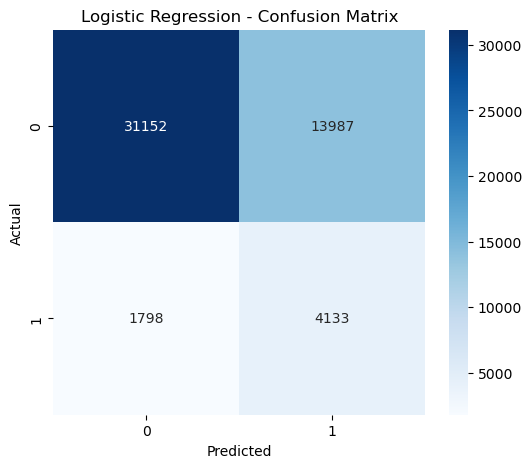

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred_logistic
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

## Classification report

In [20]:
print(
    classification_report(
        y_test,
        y_pred_logistic
    )
)

              precision    recall  f1-score   support

           0       0.95      0.69      0.80     45139
           1       0.23      0.70      0.34      5931

    accuracy                           0.69     51070
   macro avg       0.59      0.69      0.57     51070
weighted avg       0.86      0.69      0.75     51070



# Model 2 — Random Forest

In [21]:
from sklearn.ensemble import RandomForestClassifier

In [22]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=None,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [23]:
random_forest_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age', 'Income',
                                                   'LoanAmount', 'CreditScore',
                                                   'MonthsEmployed',
                                                   'NumCreditLines',
                                                   'InterestRate', 'LoanTerm',
                                                   'DTIRatio',
                                                   'LoanToIncomeRatio']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Education',
                                                   'EmploymentType',
                                                   'MaritalStatus',
                                                   'HasMortgage',
                                                   'HasDependents',
                                                   'LoanPurpose',
                                                   'HasCoSigner'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        min_samples_leaf=2, n_estimators=200,
                                        n_jobs=-1, random_state=42))])

In [24]:
y_pred_rf = random_forest_model.predict(X_test)

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

## Evaluate Random Forest

In [25]:
rf_results = {
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(y_test, y_pred_rf),
    "Recall": recall_score(y_test, y_pred_rf),
    "F1": f1_score(y_test, y_pred_rf),
    "ROC-AUC": roc_auc_score(y_test, y_prob_rf),
    "PR-AUC": average_precision_score(y_test, y_prob_rf)
}

rf_results

{'Accuracy': 0.8860387703152536,
 'Precision': 0.5684340320591862,
 'Recall': 0.07772719608834935,
 'F1': 0.13675467220409374,
 'ROC-AUC': np.float64(0.747228674033118),
 'PR-AUC': np.float64(0.3168548861695432)}

## Compare the models

In [26]:
results = pd.DataFrame([
    logistic_results,
    rf_results
], index=[
    "Logistic Regression",
    "Random Forest"
])

results

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Logistic Regression,0.690914,0.228091,0.696847,0.343686,0.761595,0.336248
Random Forest,0.886039,0.568434,0.077727,0.136755,0.747229,0.316855


# model 3 — Gradient Boosting

In [29]:
%pip install xgboost

In [30]:
from xgboost import XGBClassifier

In [31]:
xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            XGBClassifier(
                n_estimators=300,
                max_depth=6,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [32]:
xgb_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age', 'Income',
                                                   'LoanAmount', 'CreditScore',
                                                   'MonthsEmployed',
                                                   'NumCreditLines',
                                                   'InterestRate', 'LoanTerm',
                                                   'DTIRatio',
                                                   'LoanToIncomeRatio']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Education',
                                                   'EmploymentType',
                                                   'MaritalStatus',
                                                   'HasMortgage',
                                                   'HasDependents',
                                                   'Loa...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=6, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [33]:
y_pred_xgb = xgb_model.predict(X_test)

y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

In [34]:
xgb_results = {
    "Accuracy": accuracy_score(y_test, y_pred_xgb),
    "Precision": precision_score(y_test, y_pred_xgb),
    "Recall": recall_score(y_test, y_pred_xgb),
    "F1": f1_score(y_test, y_pred_xgb),
    "ROC-AUC": roc_auc_score(y_test, y_prob_xgb),
    "PR-AUC": average_precision_score(y_test, y_prob_xgb)
}

xgb_results

{'Accuracy': 0.8863716467593499,
 'Precision': 0.5901408450704225,
 'Recall': 0.07064575956836959,
 'F1': 0.1261858153892486,
 'ROC-AUC': np.float64(0.75758147030722),
 'PR-AUC': np.float64(0.33025440336369316)}

In [35]:
results = pd.DataFrame([
    logistic_results,
    rf_results,
    xgb_results
], index=[
    "Logistic Regression",
    "Random Forest",
    "XGBoost"
])

results

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Logistic Regression,0.690914,0.228091,0.696847,0.343686,0.761595,0.336248
Random Forest,0.886039,0.568434,0.077727,0.136755,0.747229,0.316855
XGBoost,0.886372,0.590141,0.070646,0.126186,0.757581,0.330254


In [37]:
import joblib


In [38]:

joblib.dump(
    logistic_model,
    "../models/logistic_baseline.pkl"
)

joblib.dump(
    random_forest_model,
    "../models/random_forest_baseline.pkl"
)
joblib.dump(
    xgb_model,
    "../models/xgboost_baseline.pkl"
)

['../models/xgboost_baseline.pkl']